In [5]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [6]:
df = pd.read_csv("Iris.csv")

In [7]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [8]:
df = df.iloc[:,1:]

In [9]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [10]:
from sklearn.preprocessing import LabelEncoder

In [11]:
encoder = LabelEncoder()

In [12]:
df['Species'] = encoder.fit_transform(df['Species'])

In [13]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [14]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]

In [15]:
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

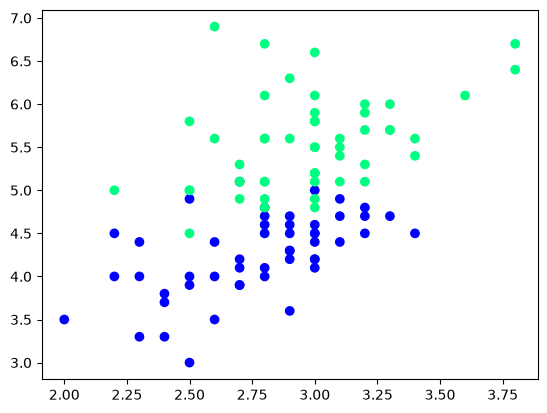

In [17]:
plt.scatter(df['SepalWidthCm'],df['PetalLengthCm'],c=df['Species'],cmap='winter')

In [18]:
df_train = df.iloc[:60,:].sample(10)
df_train

,SepalWidthCm,PetalLengthCm,Species
58,2.9,4.6,1
97,2.9,4.3,1
55,2.8,4.5,1
62,2.2,4.0,1
85,3.4,4.5,1
104,3.0,5.8,2
70,3.2,4.8,1
53,2.3,4.0,1
57,2.4,3.3,1
82,2.7,3.9,1


In [19]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [20]:
df_train

,SepalWidthCm,PetalLengthCm,Species
117,3.8,6.7,2
56,3.3,4.7,1
142,2.7,5.1,2
52,3.1,4.9,1
118,2.6,6.9,2
131,3.8,6.4,2
127,3.0,4.9,2
137,3.1,5.5,2
77,3.0,5.0,1
138,3.0,4.8,2


In [21]:
df_val

,SepalWidthCm,PetalLengthCm,Species
122,2.8,6.7,2
73,2.8,4.7,1
101,2.7,5.1,2
105,3.0,6.6,2
91,3.0,4.6,1


In [22]:
df_test

,SepalWidthCm,PetalLengthCm,Species
111,2.7,5.3,2
80,2.4,3.8,1
129,3.0,5.8,2
135,3.0,6.1,2
83,2.7,5.1,1


In [23]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [24]:
y_test

array([2, 1, 2, 2, 1])

# Case 1 - Bagging

In [25]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,SepalWidthCm,PetalLengthCm,Species
77,3.0,5.0,1
138,3.0,4.8,2
118,2.6,6.9,2
118,2.6,6.9,2
52,3.1,4.9,1
131,3.8,6.4,2
137,3.1,5.5,2
118,2.6,6.9,2


In [38]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

%pip install mlxtend
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 9.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [39]:
dt_bag1 = DecisionTreeClassifier()

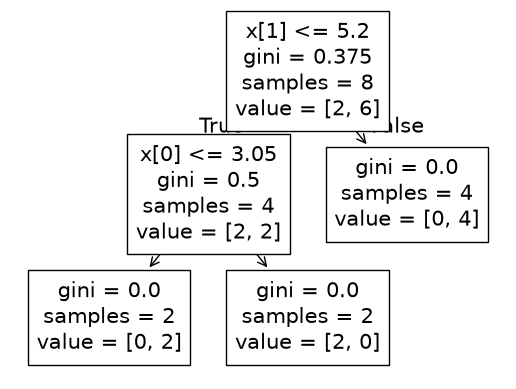

/Users/ayushthasale007/Sarg<3/PlainML/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.6


/Users/ayushthasale007/Sarg<3/PlainML/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


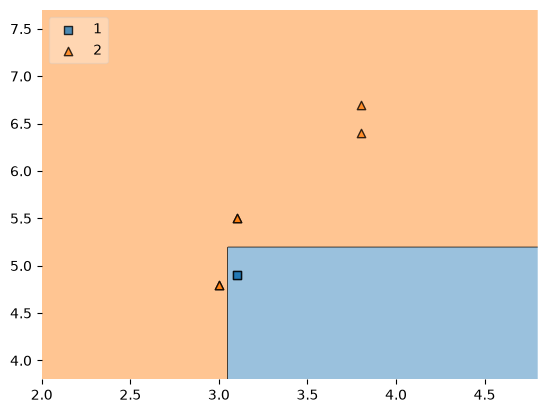

In [40]:
evaluate(dt_bag1,X,y)

In [41]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
52,3.1,4.9,1
137,3.1,5.5,2
138,3.0,4.8,2
77,3.0,5.0,1
137,3.1,5.5,2
56,3.3,4.7,1
142,2.7,5.1,2
138,3.0,4.8,2


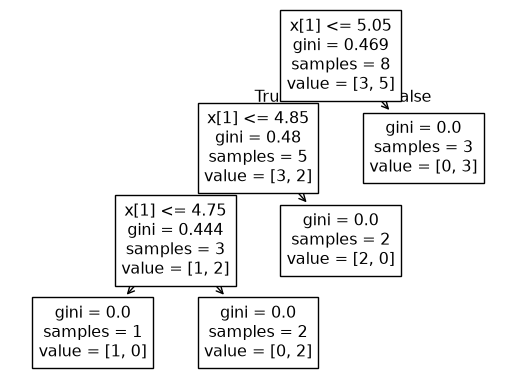

1.0


/Users/ayushthasale007/Sarg<3/PlainML/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/Users/ayushthasale007/Sarg<3/PlainML/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


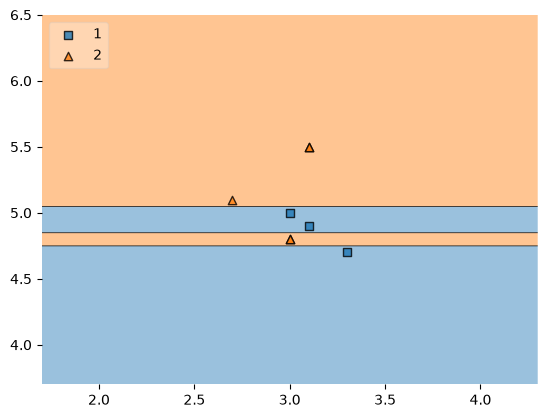

In [42]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [43]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
142,2.7,5.1,2
118,2.6,6.9,2
77,3.0,5.0,1
138,3.0,4.8,2
118,2.6,6.9,2
52,3.1,4.9,1
118,2.6,6.9,2
117,3.8,6.7,2


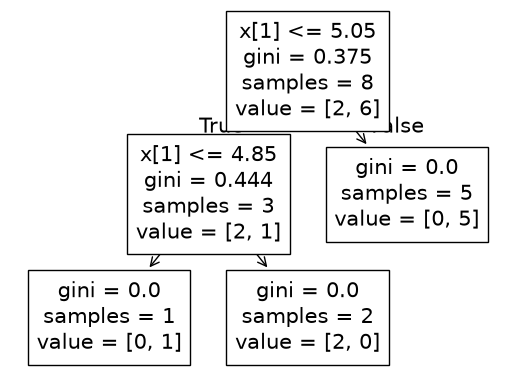

0.6


/Users/ayushthasale007/Sarg<3/PlainML/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/Users/ayushthasale007/Sarg<3/PlainML/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


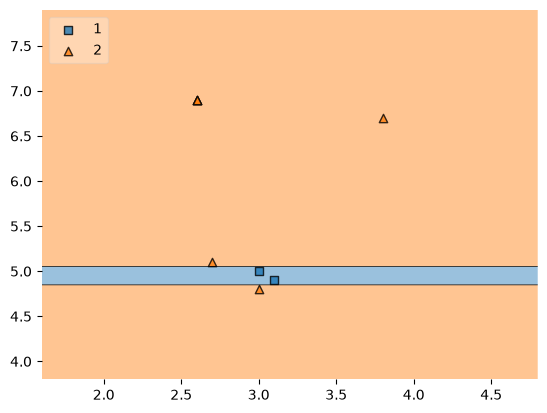

In [44]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

In [45]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))
    

## Predict

In [46]:
df_test

,SepalWidthCm,PetalLengthCm,Species
111,2.7,5.3,2
80,2.4,3.8,1
129,3.0,5.8,2
135,3.0,6.1,2
83,2.7,5.1,1


In [47]:
# print("Predictor 1",dt_bag1.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.2,5.0]).reshape(1,2)))

Predictor 2 [1]
Predictor 3 [1]


/Users/ayushthasale007/Sarg<3/PlainML/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/Users/ayushthasale007/Sarg<3/PlainML/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


# Pasting

In [48]:
# Row sampling without replacement
df_train

,SepalWidthCm,PetalLengthCm,Species
117,3.8,6.7,2
56,3.3,4.7,1
142,2.7,5.1,2
52,3.1,4.9,1
118,2.6,6.9,2
131,3.8,6.4,2
127,3.0,4.9,2
137,3.1,5.5,2
77,3.0,5.0,1
138,3.0,4.8,2


In [49]:
df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
142,2.7,5.1,2
137,3.1,5.5,2
127,3.0,4.9,2
131,3.8,6.4,2
77,3.0,5.0,1
138,3.0,4.8,2
117,3.8,6.7,2
118,2.6,6.9,2


# Random Subspaces

In [52]:
df1 = pd.read_csv('iris.csv')
df1 = df1.sample(10)

In [53]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
85,86,6.0,3.4,4.5,1.6,Iris-versicolor
126,127,6.2,2.8,4.8,1.8,Iris-virginica
57,58,4.9,2.4,3.3,1.0,Iris-versicolor
41,42,4.5,2.3,1.3,0.3,Iris-setosa
131,132,7.9,3.8,6.4,2.0,Iris-virginica
48,49,5.3,3.7,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
121,122,5.6,2.8,4.9,2.0,Iris-virginica
40,41,5.0,3.5,1.3,0.3,Iris-setosa
99,100,5.7,2.8,4.1,1.3,Iris-versicolor


In [54]:
df1.sample(2,replace=True,axis=1)

,SepalLengthCm,SepalLengthCm
85,6.0,6.0
126,6.2,6.2
57,4.9,4.9
41,4.5,4.5
131,7.9,7.9
48,5.3,5.3
4,5.0,5.0
121,5.6,5.6
40,5.0,5.0
99,5.7,5.7


# Random Patches

In [55]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
85,86,6.0,3.4,4.5,1.6,Iris-versicolor
126,127,6.2,2.8,4.8,1.8,Iris-virginica
57,58,4.9,2.4,3.3,1.0,Iris-versicolor
41,42,4.5,2.3,1.3,0.3,Iris-setosa
131,132,7.9,3.8,6.4,2.0,Iris-virginica
48,49,5.3,3.7,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
121,122,5.6,2.8,4.9,2.0,Iris-virginica
40,41,5.0,3.5,1.3,0.3,Iris-setosa
99,100,5.7,2.8,4.1,1.3,Iris-versicolor


In [56]:
df1.sample(8,replace=True).sample(2,replace=True,axis=1)

,Species,SepalWidthCm
126,Iris-virginica,2.8
48,Iris-setosa,3.7
48,Iris-setosa,3.7
48,Iris-setosa,3.7
126,Iris-virginica,2.8
40,Iris-setosa,3.5
48,Iris-setosa,3.7
131,Iris-virginica,3.8
